# Which polynomial degree is best?
**Short answer:** try degree 1, 2, 3 … and keep the one with the best **validation (CV) R²**, not the best train R².

- Train R² always goes **up** with a higher degree (the curve bends more to hit every point).
- Validation R² goes up, then **down** when the curve starts to memorise noise (**overfitting**).
- The best degree is the top of the validation curve. If two degrees are almost equal (within 0.01),
  take the **smaller** one: simpler curve, less risk on new data.

Can you see it in the data? A little: a scatter of one feature vs. y shows the shape
(straight → 1, one bend → 2, S-shape → 3). With many features you can't see it, so let CV decide.

## Setup (same as your Q1)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../titanic.csv")          # <<<
cols = ["Age", "Pclass", "SibSp"]           # <<<
target = "Fare"                             # <<<

df = df[cols + [target]].dropna()
df = df.sample(frac=1, random_state=42)
x = df[cols].values
y = df[target].values
n = int(len(df)*0.8)
x_train, x_test, y_train, y_test = x[:n], x[n:], y[:n], y[n:]


def linear(x_train, y_train, x_test):
    x_train = np.column_stack([np.ones(len(x_train)), x_train])
    x_test = np.column_stack([np.ones(len(x_test)), x_test])
    w = np.linalg.pinv(x_train.T @ x_train) @ x_train.T @ y_train
    return x_test @ w


def r2(y_test, y_pred):
    return 1 - (((y_test - y_pred) ** 2).sum() / ((y_test - y_test.mean()) ** 2).sum())

## 1. Look at the shape (one feature at a time)

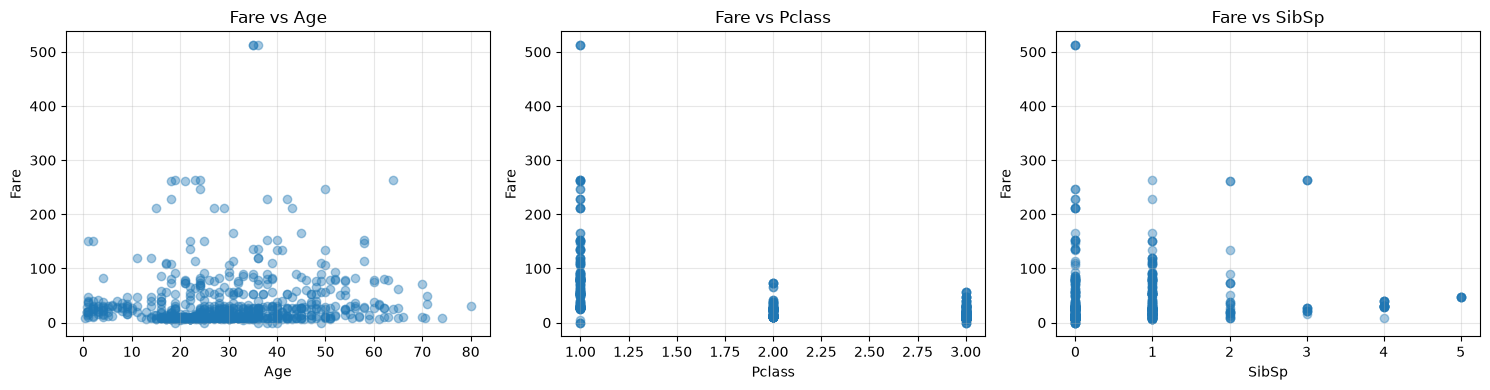

In [2]:
plt.figure(figsize=(15, 4))
for i, c in enumerate(cols, 1):
    plt.subplot(1, len(cols), i)
    plt.scatter(df[c], df[target], alpha=0.4)
    plt.xlabel(c); plt.ylabel(target); plt.title(f"{target} vs {c}")
    plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2. From scratch: try degree 1–6 with 5-fold CV
`poly(x, d)` = x, x², …, x^d. Features are scaled first, or x⁶ becomes huge.

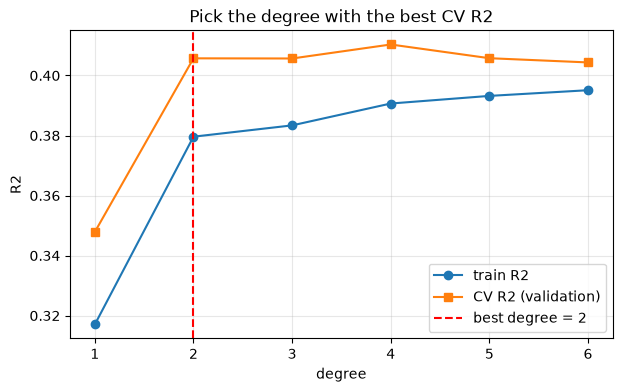

top CV degree: 4 | chosen (smallest within 0.01): 2


,degree,train R2,CV R2
0,1,0.3170,0.3479
1,2,0.3796,0.4057
2,3,0.3834,0.4057
3,4,0.3907,0.4103
4,5,0.3932,0.4058
5,6,0.3951,0.4044


In [3]:
def poly(x, d, mu, sd):
    z = (x - mu) / sd                                    # scale with TRAIN mean / std
    return np.column_stack([z ** p for p in range(1, d + 1)])


def cv_r2(x, y, d, k=5):
    folds = np.array_split(np.arange(len(y)), k)
    scores = []
    for f in folds:
        rest = np.setdiff1d(np.arange(len(y)), f)
        mu, sd = x[rest].mean(0), x[rest].std(0) + 1e-9
        p = linear(poly(x[rest], d, mu, sd), y[rest], poly(x[f], d, mu, sd))
        scores.append(r2(y[f], p))
    return np.mean(scores)


mu, sd = x_train.mean(0), x_train.std(0) + 1e-9
rows = []
for d in range(1, 7):
    train = r2(y_train, linear(poly(x_train, d, mu, sd), y_train, poly(x_train, d, mu, sd)))
    rows.append([d, train, cv_r2(x_train, y_train, d)])
res = pd.DataFrame(rows, columns=["degree", "train R2", "CV R2"])
# best = the SMALLEST degree whose CV R2 is within 0.01 of the top (simpler curve, same score)
best_d = int(res.loc[res["CV R2"] >= res["CV R2"].max() - 0.01, "degree"].min())

plt.figure(figsize=(7, 4))
plt.plot(res["degree"], res["train R2"], "o-", label="train R2")
plt.plot(res["degree"], res["CV R2"], "s-", label="CV R2 (validation)")
plt.axvline(best_d, color="r", linestyle="--", label=f"best degree = {best_d}")
plt.xlabel("degree"); plt.ylabel("R2"); plt.title("Pick the degree with the best CV R2")
plt.legend(); plt.grid(alpha=0.3)
plt.show()
print("top CV degree:", int(res.loc[res["CV R2"].idxmax(), "degree"]), "| chosen (smallest within 0.01):", best_d)
res.round(4)

## 3. Use the best degree on the test set

In [4]:
p1 = linear(poly(x_train, 2, mu, sd), y_train, poly(x_test, 2, mu, sd))
pb = linear(poly(x_train, best_d, mu, sd), y_train, poly(x_test, best_d, mu, sd))
print(f"degree 2        test R2 = {r2(y_test, p1):.4f}")
print(f"degree {best_d} (best) test R2 = {r2(y_test, pb):.4f}")
# in Q1 replace the Poly line with:
# "Poly": linear(poly(x_train, best_d, mu, sd), y_train, poly(x_test, best_d, mu, sd)),

degree 2        test R2 = 0.5072
degree 2 (best) test R2 = 0.5072


## 4. sklearn (Q2): GridSearchCV tries every degree for you
`PolynomialFeatures` also adds x₁·x₂ (interaction) terms, so the number of columns grows fast;
degree 4+ is usually too much.

In [5]:
import os, warnings
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
warnings.filterwarnings("ignore")
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression

pipe = make_pipeline(StandardScaler(), PolynomialFeatures(), LinearRegression())
grid = GridSearchCV(pipe, {"polynomialfeatures__degree": [1, 2, 3, 4, 5]}, cv=5, scoring="r2")
grid.fit(x_train, y_train)

print("best degree:", grid.best_params_["polynomialfeatures__degree"], "| CV R2:", round(grid.best_score_, 4))
print("test R2:", round(grid.score(x_test, y_test), 4))
pd.DataFrame({"degree": [1, 2, 3, 4, 5], "CV R2": grid.cv_results_["mean_test_score"]}).round(4)
# in Q2: ("Poly", grid.best_estimator_, all_cols)   or   PolynomialFeatures(best_degree)

best degree: 3 | CV R2: 0.4655
test R2: 0.5107


,degree,CV R2
0,1,0.3479
1,2,0.4526
2,3,0.4655
3,4,0.2818
4,5,-0.7013


**Write under the graph:** "Train R² keeps rising with the degree, but CV R² peaks at degree … and then falls,
so higher degrees overfit. I chose degree … by 5-fold cross-validation on the training set."